In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.manifold import TSNE


BASE = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-09-14/"
bb = pd.read_csv(BASE + "billboard.csv")
audio = pd.read_csv(BASE + "audio_features.csv")


In [ ]:
bb.head()

,url,week_id,week_position,song,performer,song_id,instance,previous_week_position,peak_position,weeks_on_chart
0,http://www.billboard.com/charts/hot-100/1965-0...,7/17/1965,34,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,45.0,34,4
1,http://www.billboard.com/charts/hot-100/1965-0...,7/24/1965,22,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,34.0,22,5
2,http://www.billboard.com/charts/hot-100/1965-0...,7/31/1965,14,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,22.0,14,6
3,http://www.billboard.com/charts/hot-100/1965-0...,8/7/1965,10,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,14.0,10,7
4,http://www.billboard.com/charts/hot-100/1965-0...,8/14/1965,8,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,10.0,8,8


In [ ]:
bb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 327895 entries, 0 to 327894
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   url                     327895 non-null  object 
 1   week_id                 327895 non-null  object 
 2   week_position           327895 non-null  int64  
 3   song                    327895 non-null  object 
 4   performer               327895 non-null  object 
 5   song_id                 327895 non-null  object 
 6   instance                327895 non-null  int64  
 7   previous_week_position  295941 non-null  float64
 8   peak_position           327895 non-null  int64  
 9   weeks_on_chart          327895 non-null  int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 25.0+ MB


In [ ]:
audio.head()

,song_id,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,spotify_track_explicit,spotify_track_album,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,spotify_track_popularity
0,-twistin'-White Silver SandsBill Black's Combo,Bill Black's Combo,-twistin'-White Silver Sands,[],NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,¿Dònde Està Santa Claus? (Where Is Santa Claus...,Augie Rios,¿Dònde Està Santa Claus? (Where Is Santa Claus?),['novelty'],NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,......And Roses And RosesAndy Williams,Andy Williams,......And Roses And Roses,"['adult standards', 'brill building pop', 'eas...",3tvqPPpXyIgKrm4PR9HCf0,https://p.scdn.co/mp3-preview/cef4883cfd1e0e53...,166106.0,False,The Essential Andy Williams,0.154,...,-14.063,1.0,0.0315,0.91100,0.000267,0.112,0.150,83.969,4.0,38.0
3,...And Then There Were DrumsSandy Nelson,Sandy Nelson,...And Then There Were Drums,"['rock-and-roll', 'space age pop', 'surf music']",1fHHq3qHU8wpRKHzhojZ4a,NaN,172066.0,False,Compelling Percussion,0.588,...,-17.278,0.0,0.0361,0.00256,0.745000,0.145,0.801,121.962,4.0,11.0
4,...Baby One More TimeBritney Spears,Britney Spears,...Baby One More Time,"['dance pop', 'pop', 'post-teen pop']",3MjUtNVVq3C8Fn0MP3zhXa,https://p.scdn.co/mp3-preview/da2134a161f1cb34...,211066.0,False,...Baby One More Time (Digital Deluxe Version),0.759,...,-5.745,0.0,0.0307,0.20200,0.000131,0.443,0.907,92.960,4.0,77.0


In [ ]:
audio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29503 entries, 0 to 29502
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   song_id                    29503 non-null  object 
 1   performer                  29503 non-null  object 
 2   song                       29503 non-null  object 
 3   spotify_genre              27903 non-null  object 
 4   spotify_track_id           24397 non-null  object 
 5   spotify_track_preview_url  14491 non-null  object 
 6   spotify_track_duration_ms  24397 non-null  float64
 7   spotify_track_explicit     24397 non-null  object 
 8   spotify_track_album        24391 non-null  object 
 9   danceability               24334 non-null  float64
 10  energy                     24334 non-null  float64
 11  key                        24334 non-null  float64
 12  loudness                   24334 non-null  float64
 13  mode                       24334 non-null  flo

In [ ]:
#Drop duplicates  for audio

print(f'Before: {audio.shape}')
audio = audio.drop_duplicates('song_id', keep='first')
print(f'After: {audio.shape}')

Before: (29503, 22)
After: (29386, 22)


In [ ]:
#Checking for N/A
features = ['danceability','energy','key','loudness','mode','speechiness',
            'acousticness','instrumentalness','liveness','valence','tempo','time_signature']
audio[features].isna().sum(axis=1).value_counts()

,count
0,24225
12,5161


In [ ]:
#Dropping NA from audio

audio_full = audio.copy() # making a copy of the full df just in case
audio = audio.dropna(subset=features)
len(audio)

24225

In [ ]:
#Converting week_id value to date

bb['week_id'] = pd.to_datetime(bb['week_id'], format='%m/%d/%Y')

#Creating separate columns to group by year month and date
bb['year'] = bb['week_id'].dt.year
bb['month'] = bb['week_id'].dt.month
bb['day'] = bb['week_id'].dt.day

In [ ]:
#Checking one song to learn more about how the columns operate
song = bb[bb['song'] == 'All I Want For Christmas Is You'].sort_values('week_id')
song[['week_id','week_position','previous_week_position','peak_position','weeks_on_chart','instance']]

,week_id,week_position,previous_week_position,peak_position,weeks_on_chart,instance
9465,2000-01-08,83,NaN,83,1,1
21839,2011-12-31,99,NaN,99,1,1
297515,2012-12-22,29,NaN,29,2,2
297874,2012-12-29,25,29.0,25,3,2
298290,2013-01-05,21,25.0,21,4,2
302772,2013-12-21,26,NaN,26,5,3
302838,2013-12-28,27,26.0,26,6,3
302896,2014-01-04,26,27.0,26,7,3
303732,2014-12-20,50,NaN,50,8,4
303748,2014-12-27,40,50.0,40,9,4


In [ ]:
#Mapping seasons to months for examining seasonality
season_map = {12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',
              6:'Summer',7:'Summer',8:'Summer',9:'Fall',10:'Fall',11:'Fall'}
bb['season'] = bb['month'].map(season_map)

# Row of each song's best rank (earliest week if tied)
peaks = (bb.sort_values(['week_position', 'week_id'])
           .drop_duplicates('song_id')
           [['song_id', 'week_position', 'week_id', 'season']]
           .rename(columns={'week_position': 'peak', 'week_id': 'peak_week', 'season': 'peak_season'}))

model_df = peaks.merge(audio, on='song_id', how='inner')

In [ ]:
model_df

,song_id,peak,peak_week,peak_season,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,spotify_track_popularity
0,Poor Little FoolRicky Nelson,1,1958-08-02,Summer,Ricky Nelson,Poor Little Fool,"['adult standards', 'brill building pop', 'bub...",5ayybTSXNwcarDtxQKqvWX,NaN,153933.0,...,-11.528,1.0,0.0299,0.6480,0.000000,0.130,0.810,154.596,4.0,56.0
1,Little StarThe Elegants,1,1958-08-23,Summer,The Elegants,Little Star,"['doo-wop', 'rhythm and blues']",3c7KT5CN8uYRaK3xThhdYt,https://p.scdn.co/mp3-preview/020ed02ce51dee8a...,162773.0,...,-12.536,1.0,0.0300,0.8730,0.000000,0.280,0.697,72.615,4.0,40.0
2,It's All In The GameTommy Edwards,1,1958-09-27,Fall,Tommy Edwards,It's All In The Game,"['deep adult standards', 'doo-wop']",2lmPUdIdzlFH64PWJrw6Zb,NaN,159040.0,...,-13.527,1.0,0.0295,0.0380,0.000000,0.309,0.654,105.181,3.0,49.0
3,It's Only Make BelieveConway Twitty,1,1958-11-08,Fall,Conway Twitty,It's Only Make Believe,"['arkansas country', 'country', 'country rock']",1xVOttVNT27FBTD8iHjOfU,NaN,132026.0,...,-9.627,1.0,0.0598,0.8600,0.000028,0.135,0.251,128.537,4.0,50.0
4,Tom DooleyThe Kingston Trio,1,1958-11-15,Fall,The Kingston Trio,Tom Dooley,"['american folk revival', 'bubblegum pop', 'fo...",2qLxtO0iaFGI9x19vU3bDI,NaN,183973.0,...,-13.842,1.0,0.0441,0.8270,0.000007,0.109,0.497,125.974,4.0,43.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24219,Boss BitchDoja Cat,100,2020-04-25,Spring,Doja Cat,Boss Bitch,"['dance pop', 'pop', 'pop rap']",78qd8dvwea0Gosb6Fe6j3k,https://p.scdn.co/mp3-preview/42847ffa3c83fcfc...,134239.0,...,-4.593,0.0,0.2220,0.1270,0.000000,0.202,0.575,125.989,4.0,83.0
24220,Worldwide BeautifulKane Brown,100,2020-06-20,Summer,Kane Brown,Worldwide Beautiful,"['contemporary country', 'country road']",431M98gFekRc9HdNfgWc7N,https://p.scdn.co/mp3-preview/728adcd7cdcd80e7...,208977.0,...,-5.953,1.0,0.0443,0.0146,0.000000,0.151,0.570,143.937,4.0,54.0
24221,"Wine, Beer, WhiskeyLittle Big Town",100,2020-11-07,Fall,Little Big Town,"Wine, Beer, Whiskey","['contemporary country', 'country', 'country d...",5avVDmK9FVJpd3MDO8I3Zl,NaN,196160.0,...,-5.850,1.0,0.0743,0.6170,0.000000,0.596,0.784,106.021,4.0,71.0
24222,Beautiful TripKid Cudi,100,2020-12-26,Winter,Kid Cudi,Beautiful Trip,"['hip hop', 'ohio hip hop', 'rap']",4IIuCotvqijraSdnVLaFnM,NaN,37013.0,...,-15.392,0.0,0.6320,0.9720,0.953000,0.882,0.420,133.971,4.0,56.0


# Descriptive

Do songs that chart in warmer months have higher energy, valence, and danceability than songs that chart in colder months, and has that seasonal pattern changed over the years?

In [ ]:
bb['season'] = bb['month'].map(season_map)   # season_map from earlier
weekly = bb.merge(audio[['song_id'] + features], on='song_id', how='inner') #getting the audio features from audio df into bb

weekly.head()

,url,week_id,week_position,song,performer,song_id,instance,previous_week_position,peak_position,weeks_on_chart,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,http://www.billboard.com/charts/hot-100/1965-0...,1965-07-17,34,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,45.0,34,4,...,7.0,-15.044,1.0,0.0298,0.61,0.000077,0.1,0.568,82.331,3.0
1,http://www.billboard.com/charts/hot-100/1965-0...,1965-07-24,22,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,34.0,22,5,...,7.0,-15.044,1.0,0.0298,0.61,0.000077,0.1,0.568,82.331,3.0
2,http://www.billboard.com/charts/hot-100/1965-0...,1965-07-31,14,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,22.0,14,6,...,7.0,-15.044,1.0,0.0298,0.61,0.000077,0.1,0.568,82.331,3.0
3,http://www.billboard.com/charts/hot-100/1965-0...,1965-08-07,10,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,14.0,10,7,...,7.0,-15.044,1.0,0.0298,0.61,0.000077,0.1,0.568,82.331,3.0
4,http://www.billboard.com/charts/hot-100/1965-0...,1965-08-14,8,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,10.0,8,8,...,7.0,-15.044,1.0,0.0298,0.61,0.000077,0.1,0.568,82.331,3.0


In [ ]:
#Shows the difference in length after joining the two DFs and dropping those with no audio features
print(f'Old length: {len(bb)}\nNew length: {len(weekly)}\nDifference: {len(bb) - len(weekly)}')

Old length: 327895
New length: 284170
Difference: 43725


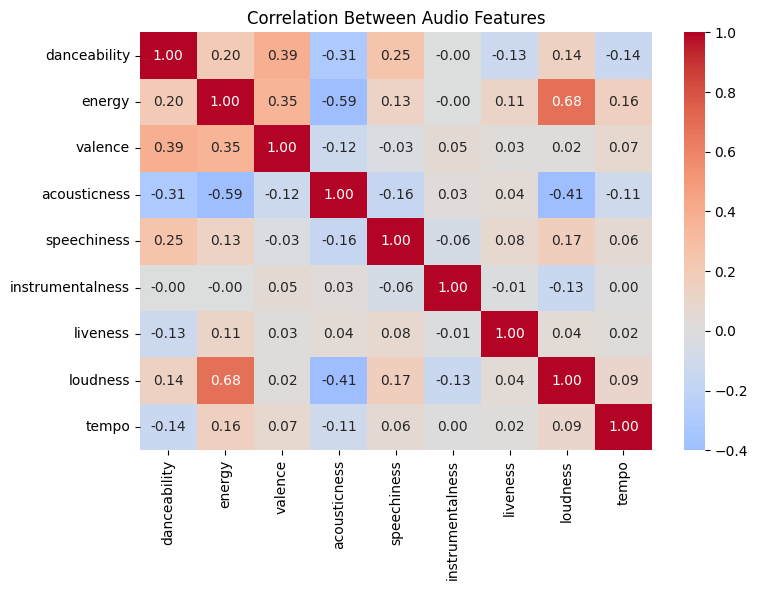

In [ ]:
#Looking for correlation in our dataset before running PCA to remove dimensionality
pca_feats = ['danceability','energy','valence','acousticness','speechiness',
             'instrumentalness','liveness','loudness','tempo']

corr = audio[pca_feats].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-0.4, vmax=1)
plt.title('Correlation Between Audio Features')
plt.tight_layout()
plt.show()

,eigenvalue,var_explained,cumulative
PC1,2.456,0.273,0.273
PC2,1.319,0.147,0.419
PC3,1.123,0.125,0.544
PC4,1.025,0.114,0.658
PC5,0.951,0.106,0.764
PC6,0.925,0.103,0.867
PC7,0.587,0.065,0.932
PC8,0.436,0.048,0.980
PC9,0.178,0.020,1.000


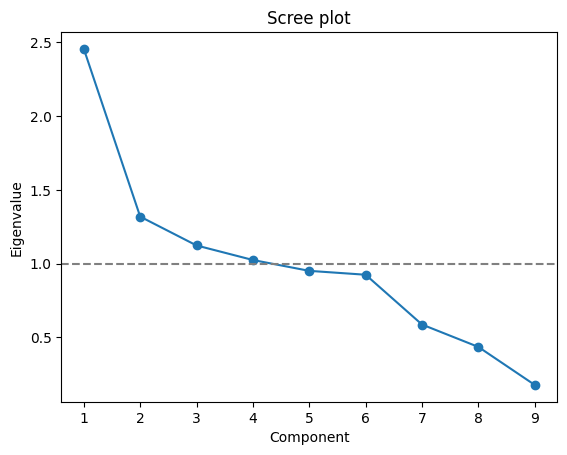

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
danceability,0.32,0.60,-0.20,0.12,0.07,-0.07,-0.16,0.64,0.18
energy,0.56,-0.15,0.19,-0.05,-0.16,0.10,0.17,-0.20,0.72
valence,0.27,0.46,0.44,0.20,-0.17,-0.42,0.23,-0.34,-0.34
acousticness,-0.48,0.02,0.04,0.21,-0.04,-0.17,0.73,0.28,0.30
speechiness,0.22,-0.00,-0.48,0.46,0.59,0.04,0.22,-0.34,-0.03
instrumentalness,-0.05,0.22,0.54,0.08,0.36,0.71,0.10,0.07,-0.07
liveness,0.03,-0.34,0.16,0.80,-0.31,0.07,-0.27,0.19,-0.05
loudness,0.47,-0.32,-0.13,-0.16,-0.16,0.18,0.47,0.35,-0.48
tempo,0.12,-0.37,0.41,-0.08,0.59,-0.48,-0.11,0.29,0.02


In [ ]:

scaler = StandardScaler().fit(audio[pca_feats])
X = scaler.transform(audio[pca_feats])
pca_full = PCA().fit(X)   # all 9 components

pcs = [f'PC{i+1}' for i in range(len(pca_feats))]

# Eigenvalues + variance explained
summary = pd.DataFrame({
    'eigenvalue': pca_full.explained_variance_,
    'var_explained': pca_full.explained_variance_ratio_,
    'cumulative': pca_full.explained_variance_ratio_.cumsum()
}, index=pcs).round(3)
display(summary)

# Scree plot
plt.plot(range(1, 10), pca_full.explained_variance_, marker='o')
plt.axhline(1, ls='--', c='gray')   # Kaiser rule: keep eigenvalue > 1
plt.xlabel('Component'); plt.ylabel('Eigenvalue'); plt.title('Scree plot')
plt.show()

# Loadings
loadings = pd.DataFrame(pca_full.components_.T, index=pca_feats, columns=pcs).round(2)
display(loadings)

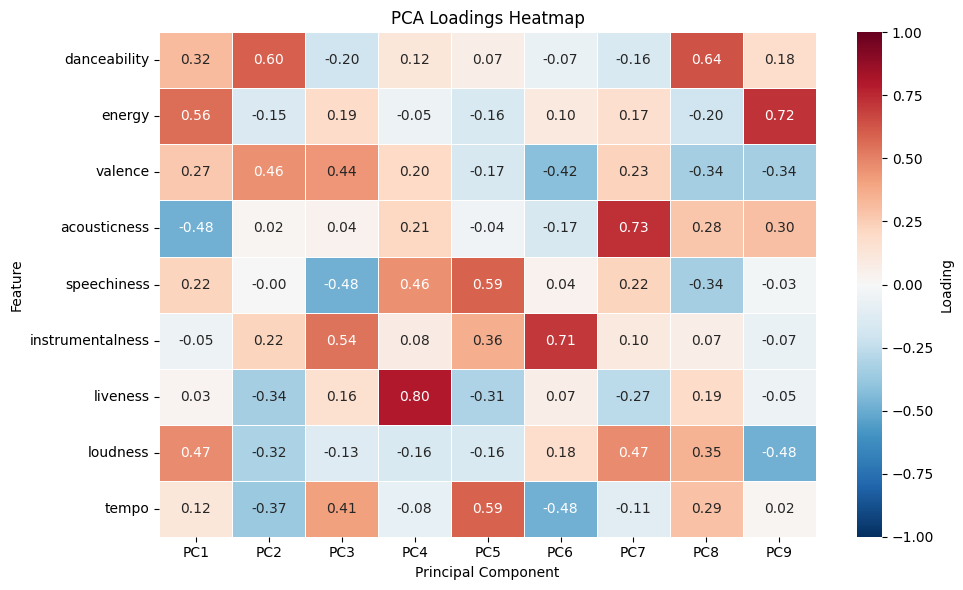

In [ ]:
# Heatmap of PCA loadings
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Loading"})
plt.title("PCA Loadings Heatmap")
plt.xlabel("Principal Component")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

| PC | Var. explained | Strongest loadings | Rough name |
|---|---|---|---|
| **PC1** | 27% | energy +0.56, acousticness −0.48, danceability +0.32 | **Intensity**: loud and electric vs. acoustic and soft |
| **PC2** | 15% | danceability +0.60, valence +0.46 | **Upbeat/groovy**: danceable, happy-sounding |
| **PC3** | 12% | instrumentalness +0.54, speechiness −0.48, valence +0.44 | **Melodic vs. spoken**: instrumental and positive vs. rap or talk-heavy |

In [ ]:
k = 3
pc_names = ['Intensity', 'Upbeat', 'Melodic_vs_Spoken']

scores = pca_full.transform(scaler.transform(weekly[pca_feats]))[:, :k]
# reading inside out:
# weekly[pca_feats]        -> the 9 features for every chart week
# scaler.transform(...)    -> rescale with the SAME mean/std learned in cell 18
# pca_full.transform(...)  -> convert to PC scores (9 columns)
# [:, :k]                  -> all rows, first 3 columns only
weekly[pc_names] = scores
# saves the 3 scores as new columns in weekly

,Intensity,Upbeat,Melodic_vs_Spoken
season,,,
Winter,-0.038,-0.021,-0.010
Spring,-0.006,0.001,-0.007
Summer,0.029,0.026,0.014
Fall,0.015,-0.006,0.003


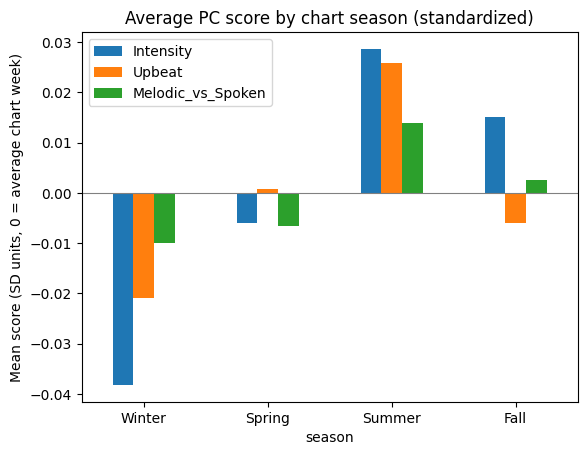

In [ ]:
season_order = ['Winter', 'Spring', 'Summer', 'Fall']

# Put each PC on the same scale (standard deviations), 0 = average chart week
z = (weekly[pc_names] - weekly[pc_names].mean()) / weekly[pc_names].std()
by_season = z.groupby(weekly['season']).mean().reindex(season_order)
display(by_season.round(3))

by_season.plot(kind='bar')
plt.axhline(0, c='gray', lw=0.8)
plt.title('Average PC score by chart season (standardized)')
plt.ylabel('Mean score (SD units, 0 = average chart week)')
plt.xticks(rotation=0); plt.show()

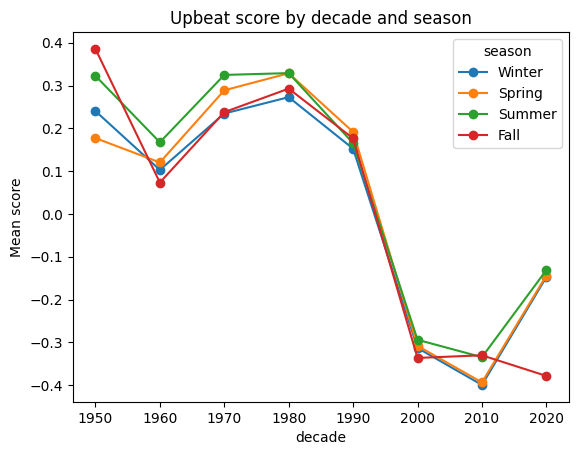

In [ ]:
weekly['decade'] = (weekly['year'] // 10) * 10
#division that drops the remainder: 1987 // 10 = 198, × 10 = 1980
by_dec = weekly.groupby(['decade', 'season'])['Upbeat'].mean().unstack()[season_order]
by_dec.plot(marker='o')
plt.title('Upbeat score by decade and season'); plt.ylabel('Mean score')
plt.show()

t-sne

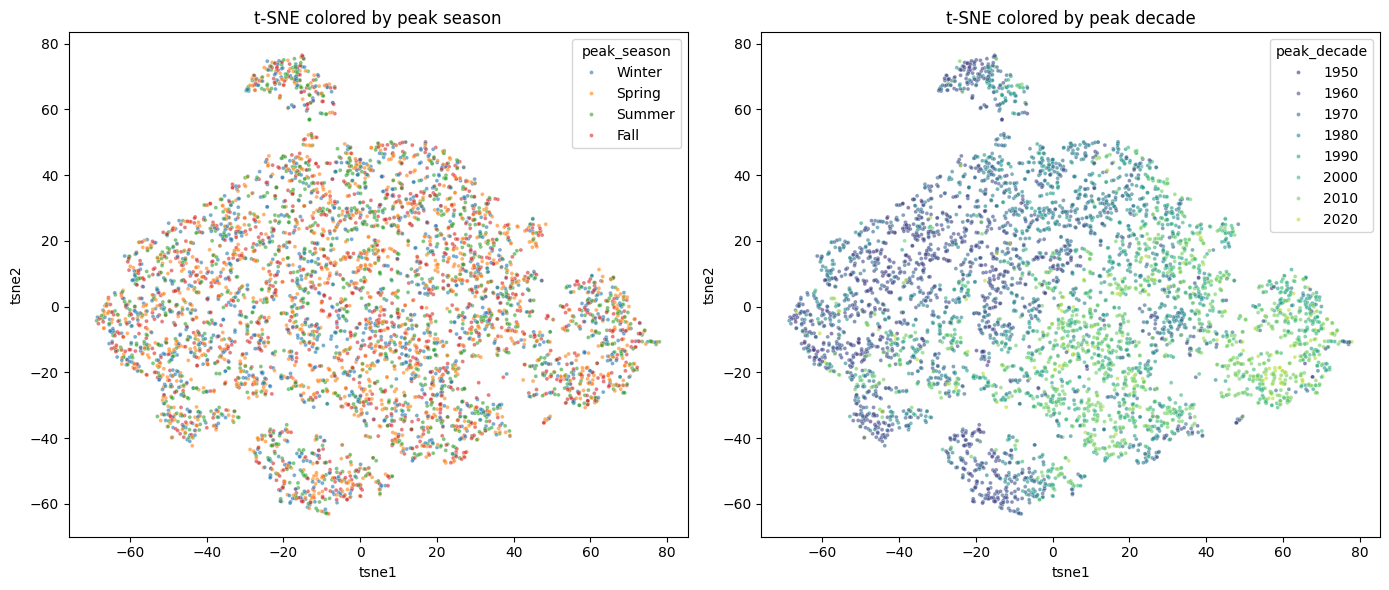

In [ ]:
'''
DONE BY AI, still need to check code
'''
# 1. Sample songs (t-SNE is slow on 24k)
sample = model_df.sample(5000, random_state=42).copy()
sample['peak_decade'] = (sample['peak_week'].dt.year // 10) * 10
sample['peak_decade'] = sample['peak_decade'].astype(str)   # moved here: treat decade as a category

# 2. Standardize with the same scaler as PCA, then run t-SNE
X_s = scaler.transform(sample[pca_feats])
emb = TSNE(n_components=2, perplexity=30, init='pca', random_state=42).fit_transform(X_s)
sample['tsne1'], sample['tsne2'] = emb[:, 0], emb[:, 1]

# 3. Plot: colored by season, and by decade
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=sample, x='tsne1', y='tsne2', hue='peak_season',
                hue_order=['Winter','Spring','Summer','Fall'], s=8, alpha=0.6, ax=ax[0])
ax[0].set_title('t-SNE colored by peak season')
sns.scatterplot(data=sample, x='tsne1', y='tsne2', hue='peak_decade',
                hue_order=sorted(sample['peak_decade'].unique()),
                palette='viridis', s=8, alpha=0.6, ax=ax[1])
ax[1].set_title('t-SNE colored by peak decade')
plt.tight_layout(); plt.show()